# Vietnamese clinical assertion experiments

GPU: Tesla T4
PyTorch: 2.11.0+cu128
Qwen: Qwen/Qwen3-8B
BGE-M3: BAAI/bge-m3


## Benchmark

,id,entity,sentence,isFamily,isHistorical,isNegated,isUncertain
0,1,đau ngực,Bệnh nhân nhập viện vì [ENTITY] khởi phát sáng...,False,False,False,False
1,2,khó thở,Hiện tại người bệnh còn [ENTITY] khi đi lại.,False,False,False,False
2,3,sốt,Khám lúc vào viện ghi nhận [ENTITY] 39 độ C.,False,False,False,False
3,4,amlodipine,Bệnh nhân đang dùng [ENTITY] mỗi sáng theo đơn.,False,False,False,False
4,5,nhiễm khuẩn huyết,Chẩn đoán xác định là [ENTITY] dựa trên cấy máu.,False,False,False,False
5,6,đau,Lý do đến khám hôm nay là [ENTITY] vùng thượng...,False,False,False,False
6,7,chóng mặt,Người bệnh mô tả [ENTITY] liên tục từ 8 giờ sáng.,False,False,False,False
7,8,nôn,"Tại khoa cấp cứu, bệnh nhân xuất hiện [ENTITY].",False,False,False,False
8,9,viêm phổi,Bác sĩ xác nhận bệnh nhân mắc [ENTITY] và bắt ...,False,False,False,False
9,10,metformin,Thuốc đang sử dụng là [ENTITY] 500 mg hai lần ...,False,False,False,False


Examples: 50
Positive labels:


,positive_count
isFamily,13
isHistorical,14
isNegated,12
isUncertain,11


... (41 outputs left out)

# Results

,pipeline,exact_match_accuracy,micro_f1,macro_f1,micro_precision,micro_recall,macro_precision,macro_recall,estimated_seconds,qwen_seconds,qwen_examples,generation_batches,rule_resolved,fallback_rate,parse_errors
3,Rule -> BGE -> Qwen,92.0%,0.962,0.963,0.926,1.000,0.930,1.000,42.3,21.7,10,3,40,20.0%,0
2,Rule -> Qwen,92.0%,0.962,0.963,0.926,1.000,0.930,1.000,21.8,21.8,10,3,40,20.0%,0
0,Qwen only,86.0%,0.914,0.916,0.873,0.960,0.891,0.958,99.2,99.2,50,13,0,100.0%,0
1,BGE -> Qwen,84.0%,0.889,0.892,0.898,0.880,0.908,0.881,201.2,98.4,50,13,0,100.0%,0


## Per-tag metrics

tag,isFamily,isHistorical,isNegated,isUncertain
pipeline,,,,
BGE -> Qwen,0.960,0.828,0.909,0.870
Qwen only,1.000,0.875,0.909,0.880
Rule -> BGE -> Qwen,0.963,0.933,1.000,0.957
Rule -> Qwen,0.963,0.933,1.000,0.957


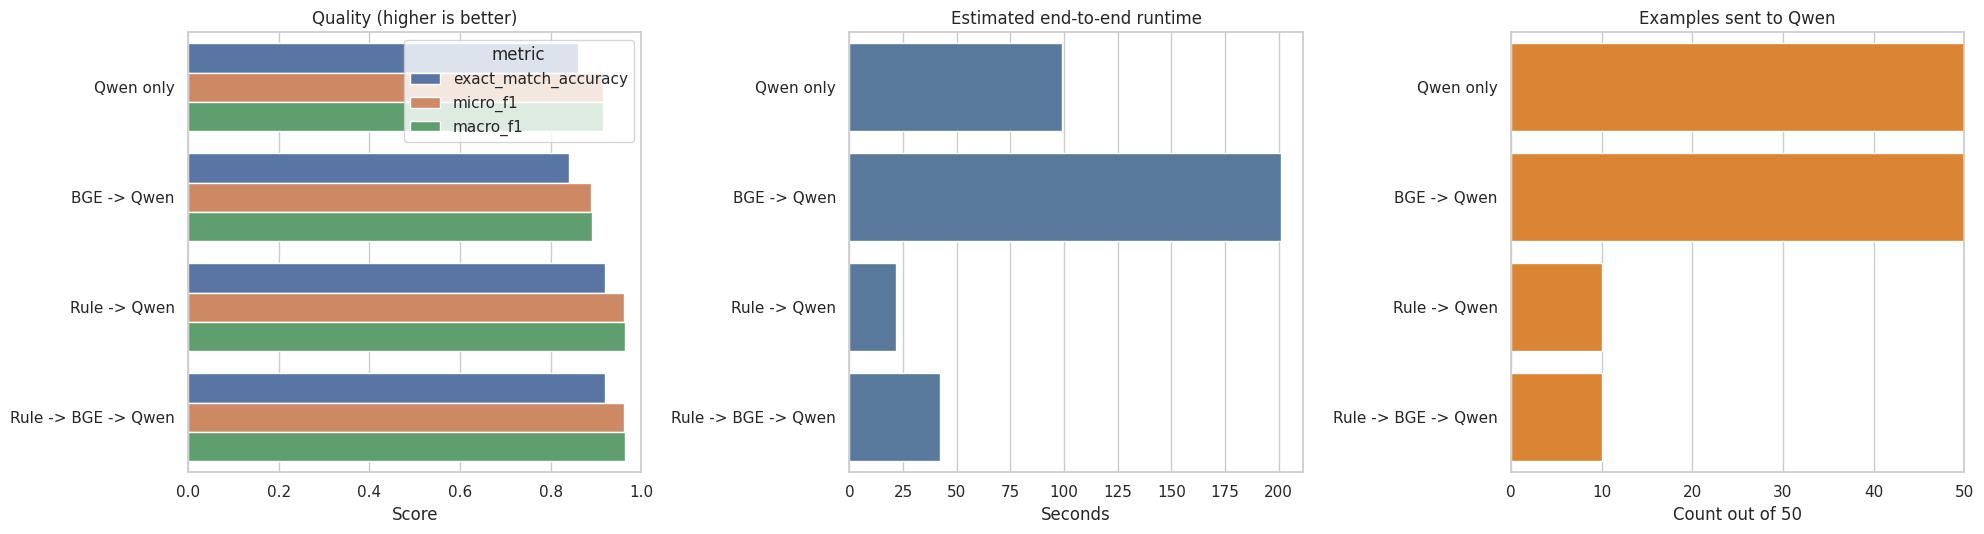

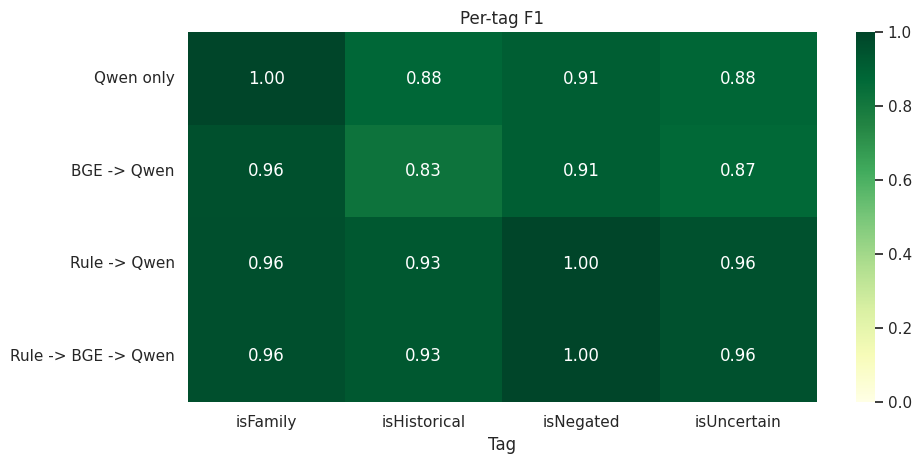

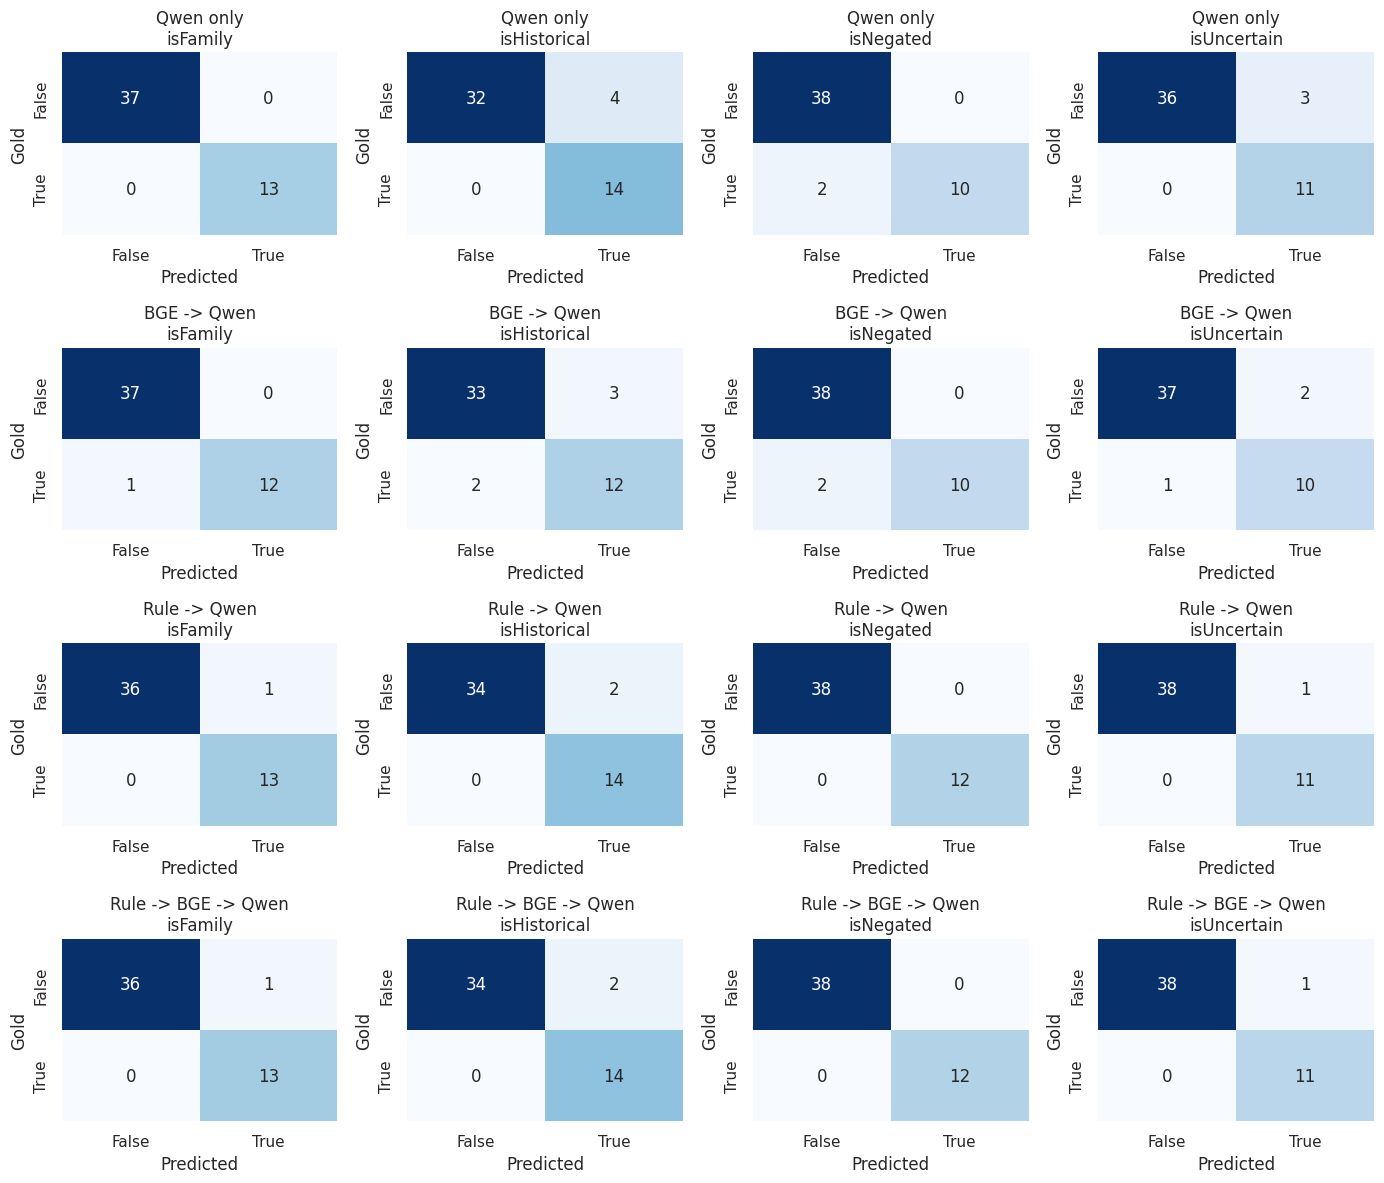

## All 50 examples, side by side

,id,entity,sentence,gold,bge_candidates,Qwen only,BGE -> Qwen,Rule -> Qwen,Rule -> BGE -> Qwen
0,1,đau ngực,Bệnh nhân nhập viện vì [ENTITY] khởi phát sáng nay.,NONE,"isFamily, isHistorical, isUncertain",NONE,NONE,NONE,NONE
1,2,khó thở,Hiện tại người bệnh còn [ENTITY] khi đi lại.,NONE,"isFamily, isHistorical, isUncertain",NONE,NONE,NONE,NONE
2,3,sốt,Khám lúc vào viện ghi nhận [ENTITY] 39 độ C.,NONE,"isFamily, isHistorical, isUncertain",isHistorical,isHistorical,isHistorical,isHistorical
3,4,amlodipine,Bệnh nhân đang dùng [ENTITY] mỗi sáng theo đơn.,NONE,"isFamily, isHistorical, isUncertain",NONE,NONE,NONE,NONE
4,5,nhiễm khuẩn huyết,Chẩn đoán xác định là [ENTITY] dựa trên cấy máu.,NONE,"isFamily, isHistorical, isUncertain",NONE,NONE,NONE,NONE
5,6,đau,Lý do đến khám hôm nay là [ENTITY] vùng thượng vị.,NONE,"isHistorical, isUncertain",NONE,NONE,NONE,NONE
6,7,chóng mặt,Người bệnh mô tả [ENTITY] liên tục từ 8 giờ sáng.,NONE,"isFamily, isHistorical, isUncertain",NONE,NONE,NONE,NONE
7,8,nôn,"Tại khoa cấp cứu, bệnh nhân xuất hiện [ENTITY].",NONE,"isFamily, isHistorical, isUncertain",NONE,NONE,NONE,NONE
8,9,viêm phổi,Bác sĩ xác nhận bệnh nhân mắc [ENTITY] và bắt đầu điều trị.,NONE,"isFamily, isHistorical, isUncertain",NONE,NONE,NONE,NONE
9,10,metformin,Thuốc đang sử dụng là [ENTITY] 500 mg hai lần mỗi ngày.,NONE,"isFamily, isHistorical, isUncertain",NONE,NONE,NONE,NONE


## Errors only

,pipeline,id,entity,sentence,gold,predicted,bge_candidates,model_or_rule_output,parse_error
0,Qwen only,3,sốt,Khám lúc vào viện ghi nhận [ENTITY] 39 độ C.,NONE,isHistorical,"isFamily, isHistorical, isUncertain","{""isFamily"": false, ""isHistorical"": true, ""isN...",None
1,BGE -> Qwen,3,sốt,Khám lúc vào viện ghi nhận [ENTITY] 39 độ C.,NONE,isHistorical,"isFamily, isHistorical, isUncertain","{""isFamily"": false, ""isHistorical"": true, ""isN...",None
2,Rule -> Qwen,3,sốt,Khám lúc vào viện ghi nhận [ENTITY] 39 độ C.,NONE,isHistorical,"isFamily, isHistorical, isUncertain","{""isFamily"": false, ""isHistorical"": true, ""isN...",None
3,Rule -> BGE -> Qwen,3,sốt,Khám lúc vào viện ghi nhận [ENTITY] 39 độ C.,NONE,isHistorical,"isFamily, isHistorical, isUncertain","{""isFamily"": false, ""isHistorical"": true, ""isN...",None
4,Qwen only,11,nôn ói,Bệnh nhân phủ nhận [ENTITY] trong 24 giờ qua.,isNegated,"isHistorical, isNegated","isFamily, isNegated, isUncertain","{""isFamily"": false, ""isHistorical"": true, ""isN...",None
5,Qwen only,14,viêm phổi,Chưa thấy bằng chứng của [ENTITY] trên phim chụp.,isNegated,isUncertain,"isNegated, isUncertain","{""isFamily"": false, ""isHistorical"": false, ""is...",None
6,BGE -> Qwen,14,viêm phổi,Chưa thấy bằng chứng của [ENTITY] trên phim chụp.,isNegated,isUncertain,"isNegated, isUncertain","{""isFamily"": false, ""isHistorical"": false, ""is...",None
7,Qwen only,15,đau bụng,Bệnh nhân hoàn toàn không còn [ENTITY] sau điề...,isNegated,"isHistorical, isNegated","isHistorical, isNegated","{""isFamily"": false, ""isHistorical"": true, ""isN...",None
8,BGE -> Qwen,15,đau bụng,Bệnh nhân hoàn toàn không còn [ENTITY] sau điề...,isNegated,"isHistorical, isNegated","isHistorical, isNegated","{""isFamily"": false, ""isHistorical"": true, ""isN...",None
9,Qwen only,17,warfarin,Người bệnh bác bỏ việc từng dùng [ENTITY].,isNegated,"isHistorical, isNegated","isHistorical, isNegated, isUncertain","{""isFamily"": false, ""isHistorical"": true, ""isN...",None


# Finished

Saved: /content/assertion_experiment_results.zip
Best pipeline by macro F1:


,pipeline,exact_match_accuracy,micro_f1,macro_f1,micro_precision,micro_recall,macro_precision,macro_recall,estimated_seconds,qwen_seconds,qwen_examples,generation_batches,rule_resolved,fallback_rate,parse_errors
3,Rule -> BGE -> Qwen,0.92,0.961538,0.963205,0.925926,1.0,0.93006,1.0,42.278212,21.72181,10,3,40,0.2,0


In [1]:
# Paste this entire file into ONE Google Colab code cell and run it.
# Runtime -> Change runtime type -> T4 GPU.

import os
import sys
import subprocess
import warnings

os.environ["TOKENIZERS_PARALLELISM"] = "false"
warnings.filterwarnings("ignore")

# -----------------------------------------------------------------------------
# 0. Install dependencies
# -----------------------------------------------------------------------------

PACKAGES = [
    "transformers>=4.51.0",
    "accelerate>=1.6.0",
    "bitsandbytes>=0.45.5",
    "sentence-transformers>=4.1.0",
    "scikit-learn>=1.4.0",
    "pandas>=2.0.0",
    "seaborn>=0.13.0",
]
subprocess.check_call(
    [sys.executable, "-m", "pip", "install", "-q", "-U", *PACKAGES]
)

import gc
import json
import math
import random
import re
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import Markdown, display
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sentence_transformers import SentenceTransformer
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


# -----------------------------------------------------------------------------
# 1. Reproducibility and experiment configuration
# -----------------------------------------------------------------------------

SEED = 42
QWEN_MODEL_ID = "Qwen/Qwen3-8B"
BGE_MODEL_ID = "BAAI/bge-m3"

QWEN_BATCH_SIZE = 4       # Change to 2 if your T4 runs out of memory.
MAX_INPUT_TOKENS = 768
MAX_NEW_TOKENS = 96

# BGE keeps at least two tags. It adds a third tag only when its score is close
# to the second tag. Therefore one or two tags are normally filtered out.
BGE_MIN_TAGS = 2
BGE_MAX_TAGS = 3
BGE_MARGIN = 0.035

TAGS = ["isFamily", "isHistorical", "isNegated", "isUncertain"]
TAG_ORDER = {tag: index for index, tag in enumerate(TAGS)}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

assert torch.cuda.is_available(), (
    "No GPU found. In Colab choose Runtime > Change runtime type > T4 GPU."
)

display(Markdown("# Vietnamese clinical assertion experiments"))
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("Qwen:", QWEN_MODEL_ID)
print("BGE-M3:", BGE_MODEL_ID)


# -----------------------------------------------------------------------------
# 2. Fixed 50-example gold benchmark
# -----------------------------------------------------------------------------

def expected(*active_tags):
    active_tags = set(active_tags)
    return {tag: tag in active_tags for tag in TAGS}


RAW_CASES = [
    # Current / affirmed / patient (10)
    ("Bệnh nhân nhập viện vì [ENTITY] khởi phát sáng nay.", "đau ngực", expected()),
    ("Hiện tại người bệnh còn [ENTITY] khi đi lại.", "khó thở", expected()),
    ("Khám lúc vào viện ghi nhận [ENTITY] 39 độ C.", "sốt", expected()),
    ("Bệnh nhân đang dùng [ENTITY] mỗi sáng theo đơn.", "amlodipine", expected()),
    ("Chẩn đoán xác định là [ENTITY] dựa trên cấy máu.", "nhiễm khuẩn huyết", expected()),
    ("Lý do đến khám hôm nay là [ENTITY] vùng thượng vị.", "đau", expected()),
    ("Người bệnh mô tả [ENTITY] liên tục từ 8 giờ sáng.", "chóng mặt", expected()),
    ("Tại khoa cấp cứu, bệnh nhân xuất hiện [ENTITY].", "nôn", expected()),
    ("Bác sĩ xác nhận bệnh nhân mắc [ENTITY] và bắt đầu điều trị.", "viêm phổi", expected()),
    ("Thuốc đang sử dụng là [ENTITY] 500 mg hai lần mỗi ngày.", "metformin", expected()),

    # Negated (8)
    ("Bệnh nhân phủ nhận [ENTITY] trong 24 giờ qua.", "nôn ói", expected("isNegated")),
    ("Khám hiện tại không ghi nhận [ENTITY].", "phù chân", expected("isNegated")),
    ("Người bệnh không có [ENTITY] kèm theo.", "sốt", expected("isNegated")),
    ("Chưa thấy bằng chứng của [ENTITY] trên phim chụp.", "viêm phổi", expected("isNegated")),
    ("Bệnh nhân hoàn toàn không còn [ENTITY] sau điều trị.", "đau bụng", expected("isNegated")),
    ("Kết quả đánh giá loại trừ [ENTITY].", "thuyên tắc phổi", expected("isNegated")),
    ("Người bệnh bác bỏ việc từng dùng [ENTITY].", "warfarin", expected("isNegated")),
    ("Không phát hiện dấu hiệu gợi ý [ENTITY] ở lần khám này.", "suy tim", expected("isNegated")),

    # Historical (8)
    ("Bệnh nhân có tiền sử [ENTITY] đã điều trị ổn định.", "hen phế quản", expected("isHistorical")),
    ("Ba năm trước người bệnh từng mắc [ENTITY].", "lao phổi", expected("isHistorical")),
    ("[ENTITY] đã xảy ra năm 2019 và hiện không tái phát.", "nhồi máu cơ tim", expected("isHistorical")),
    ("Trước đây bệnh nhân được phẫu thuật vì [ENTITY].", "viêm ruột thừa", expected("isHistorical")),
    ("Hồ sơ cũ ghi nhận [ENTITY] cách đây sáu tháng.", "xuất huyết tiêu hóa", expected("isHistorical")),
    ("Người bệnh đã khỏi [ENTITY] từ thời thơ ấu.", "thủy đậu", expected("isHistorical")),
    ("Trong lần nhập viện trước, bệnh nhân được chẩn đoán [ENTITY].", "viêm tụy cấp", expected("isHistorical")),
    ("Bệnh nhân nhớ đã trải qua [ENTITY] nhiều năm về trước.", "co giật", expected("isHistorical")),

    # Family (8)
    ("Mẹ bệnh nhân hiện đang điều trị [ENTITY].", "ung thư vú", expected("isFamily")),
    ("Anh trai của người bệnh mắc [ENTITY].", "đái tháo đường", expected("isFamily")),
    ("[ENTITY] được ghi nhận ở con gái bệnh nhân.", "hen suyễn", expected("isFamily")),
    ("Bố của bệnh nhi đang dùng thuốc cho [ENTITY].", "tăng huyết áp", expected("isFamily")),
    ("Theo lời kể, chị ruột bệnh nhân có [ENTITY].", "lupus ban đỏ", expected("isFamily")),
    ("Tình trạng [ENTITY] thuộc về chồng của bệnh nhân.", "suy thận", expected("isFamily")),
    ("Thân mẫu người bệnh được xác định mắc [ENTITY].", "ung thư đại tràng", expected("isFamily")),
    ("Một người con của bệnh nhân đang điều trị [ENTITY].", "động kinh", expected("isFamily")),

    # Uncertain (8)
    ("Nghi ngờ [ENTITY], cần làm thêm xét nghiệm.", "viêm ruột thừa", expected("isUncertain")),
    ("Có thể bệnh nhân bị [ENTITY] nhưng chưa xác định.", "sốt xuất huyết", expected("isUncertain")),
    ("Chưa rõ người bệnh có [ENTITY] hay không.", "nhiễm trùng huyết", expected("isUncertain")),
    ("Bác sĩ đặt vấn đề [ENTITY] và tiếp tục theo dõi.", "viêm cơ tim", expected("isUncertain")),
    ("Hình ảnh gợi ý [ENTITY], chờ xét nghiệm xác nhận.", "u phổi", expected("isUncertain")),
    ("Khả năng cao là [ENTITY] nhưng chẩn đoán chưa chính thức.", "viêm màng não", expected("isUncertain")),
    ("Theo dõi [ENTITY] do biểu hiện chưa điển hình.", "tắc ruột", expected("isUncertain")),
    ("Tổn thương được mô tả là [ENTITY] không đặc hiệu.", "viêm mô mềm", expected("isUncertain")),

    # Combined labels (8)
    ("Tiền sử gia đình: anh trai từng mắc [ENTITY] năm 2015.", "lao phổi", expected("isFamily", "isHistorical")),
    ("Không ai trong gia đình được ghi nhận mắc [ENTITY].", "đái tháo đường", expected("isFamily", "isNegated")),
    ("Mẹ bệnh nhân có thể mắc [ENTITY] nhưng chưa khám xác nhận.", "ung thư tuyến giáp", expected("isFamily", "isUncertain")),
    ("Tiền sử: không ghi nhận [ENTITY] trước đây.", "dị ứng thuốc", expected("isHistorical", "isNegated")),
    ("Hai năm trước từng nghi ngờ [ENTITY] nhưng chưa được xác nhận.", "viêm gan B", expected("isHistorical", "isUncertain")),
    ("Trước đây chưa thấy bằng chứng của [ENTITY].", "bệnh mạch vành", expected("isHistorical", "isNegated")),
    ("Không có ai trong gia đình từng bị [ENTITY] trước đây.", "động kinh", expected("isFamily", "isHistorical", "isNegated")),
    ("Tiền sử gia đình: ông nội nghi có [ENTITY] nhiều năm trước.", "đột quỵ", expected("isFamily", "isHistorical", "isUncertain")),
]

assert len(RAW_CASES) == 50

CASES = [
    {
        "id": index,
        "sentence": sentence,
        "entity": entity,
        "expected": gold,
    }
    for index, (sentence, entity, gold) in enumerate(RAW_CASES, start=1)
]

benchmark_df = pd.DataFrame(
    {
        "id": [case["id"] for case in CASES],
        "entity": [case["entity"] for case in CASES],
        "sentence": [case["sentence"] for case in CASES],
        **{
            tag: [case["expected"][tag] for case in CASES]
            for tag in TAGS
        },
    }
)

display(Markdown("## Benchmark"))
display(benchmark_df.head(10))
print("Examples:", len(benchmark_df))
print("Positive labels:")
display(benchmark_df[TAGS].sum().rename("positive_count").to_frame())


# -----------------------------------------------------------------------------
# 3. Conservative rule-based classifier
# -----------------------------------------------------------------------------

RULE_PATTERNS = {
    "isFamily": [
        r"\b(?:cha|ba|bố|mẹ|má|anh|chị|em|ông|bà|cô|dì|chú|cậu|mợ|vợ|chồng|con)\b",
        r"\b(?:gia đình|thân nhân|thân mẫu|thân phụ|người nhà)\b",
    ],
    "isHistorical": [
        r"\b(?:tiền sử|trước đây|từng|đã từng|hồ sơ cũ|lần nhập viện trước)\b",
        r"\b(?:cách đây|năm 19\d{2}|năm 20\d{2}|nhiều năm về trước)\b",
        r"\bđã (?:xảy ra|khỏi)\b",
    ],
    "isNegated": [
        r"\b(?:không|chẳng|chưa)\s+(?:có|ghi nhận|thấy|phát hiện|còn)\b",
        r"\b(?:phủ nhận|loại trừ|bác bỏ)\b",
        r"\bkhông (?:ai|còn|kèm theo)\b",
    ],
    "isUncertain": [
        r"\b(?:nghi ngờ|nghi có|có thể|chưa rõ|gợi ý|khả năng cao)\b",
        r"\b(?:đặt vấn đề|theo dõi|chưa xác định|chưa chính thức|không đặc hiệu)\b",
    ],
}
RULE_PATTERNS = {
    tag: [re.compile(pattern, re.IGNORECASE) for pattern in patterns]
    for tag, patterns in RULE_PATTERNS.items()
}


def rule_classify(sentence):
    """Return (prediction, evidence) or (None, {}) when rules abstain."""
    evidence = {}
    prediction = {tag: False for tag in TAGS}
    for tag, patterns in RULE_PATTERNS.items():
        for pattern in patterns:
            match = pattern.search(sentence)
            if match:
                prediction[tag] = True
                evidence[tag] = match.group(0)
                break
    if not evidence:
        return None, {}
    return prediction, evidence


rule_preview = []
for case in CASES:
    pred, evidence = rule_classify(case["sentence"])
    rule_preview.append(
        {
            "id": case["id"],
            "resolved_by_rule": pred is not None,
            "rule_tags": [tag for tag in TAGS if pred and pred[tag]],
            "evidence": evidence,
        }
    )
rule_preview_df = pd.DataFrame(rule_preview)
display(Markdown("## Rule coverage before loading models"))
display(rule_preview_df.head(10))
print(f"Rule coverage: {rule_preview_df['resolved_by_rule'].mean():.1%}")


# -----------------------------------------------------------------------------
# 4. BGE-M3 candidate-tag filtering
# -----------------------------------------------------------------------------

# These prototype phrases are derived from the project's assertion template
# families. They are deliberately separate from the 50 gold examples.
TAG_PROTOTYPES = {
    "isFamily": [
        "Tiền sử gia đình có [ENTITY].",
        "Cha của bệnh nhân mắc [ENTITY].",
        "Mẹ người bệnh được chẩn đoán [ENTITY].",
        "Anh chị em ruột ghi nhận [ENTITY].",
        "Con của bệnh nhân đang điều trị [ENTITY].",
        "Ông bà bên nội có [ENTITY].",
        "Người thân của bệnh nhân bị [ENTITY].",
        "[ENTITY] xuất hiện ở thành viên gia đình.",
    ],
    "isHistorical": [
        "Bệnh nhân có tiền sử [ENTITY].",
        "Trước đây người bệnh từng mắc [ENTITY].",
        "[ENTITY] xảy ra nhiều năm trước.",
        "Đã điều trị [ENTITY] trong lần nhập viện cũ.",
        "Hồ sơ trước kia ghi nhận [ENTITY].",
        "Bệnh nhân đã khỏi [ENTITY].",
        "Cách đây hai năm có [ENTITY].",
        "[ENTITY] là bệnh sử trong quá khứ.",
    ],
    "isNegated": [
        "Bệnh nhân không có [ENTITY].",
        "Người bệnh phủ nhận [ENTITY].",
        "Không ghi nhận [ENTITY].",
        "Chưa phát hiện [ENTITY].",
        "Không thấy bằng chứng [ENTITY].",
        "Đã loại trừ [ENTITY].",
        "[ENTITY] âm tính.",
        "Bệnh nhân chưa từng bị [ENTITY].",
    ],
    "isUncertain": [
        "Nghi ngờ bệnh nhân có [ENTITY].",
        "Có thể là [ENTITY].",
        "Chưa rõ có [ENTITY] hay không.",
        "Theo dõi [ENTITY].",
        "Hình ảnh gợi ý [ENTITY].",
        "Chưa loại trừ [ENTITY].",
        "[ENTITY] chưa được xác nhận.",
        "Chẩn đoán [ENTITY] không đặc hiệu.",
    ],
}


def select_candidate_tags(tag_scores):
    ranked = sorted(TAGS, key=lambda tag: tag_scores[tag], reverse=True)
    selected = ranked[:BGE_MIN_TAGS]
    cutoff = tag_scores[ranked[BGE_MIN_TAGS - 1]] - BGE_MARGIN
    for tag in ranked[BGE_MIN_TAGS:]:
        if len(selected) >= BGE_MAX_TAGS:
            break
        if tag_scores[tag] >= cutoff:
            selected.append(tag)
    return sorted(selected, key=TAG_ORDER.get)


display(Markdown("## Loading BGE-M3 and filtering candidate tags"))
bge_started = time.perf_counter()
bge_model = SentenceTransformer(BGE_MODEL_ID, device="cuda")

prototype_texts = []
prototype_tags = []
for tag, texts in TAG_PROTOTYPES.items():
    prototype_texts.extend(texts)
    prototype_tags.extend([tag] * len(texts))

prototype_embeddings = bge_model.encode(
    prototype_texts,
    batch_size=32,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True,
)
query_embeddings = bge_model.encode(
    [case["sentence"] for case in CASES],
    batch_size=32,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True,
)

similarity = query_embeddings @ prototype_embeddings.T
BGE_INFO = {}
for row_index, case in enumerate(CASES):
    scores = {}
    for tag in TAGS:
        indices = [i for i, prototype_tag in enumerate(prototype_tags) if prototype_tag == tag]
        scores[tag] = float(similarity[row_index, indices].max())
    BGE_INFO[case["id"]] = {
        "scores": scores,
        "candidates": select_candidate_tags(scores),
    }

bge_elapsed_all = time.perf_counter() - bge_started

# Positive-label candidate recall. All-negative cases are excluded because
# there is no positive gold tag to retrieve.
positive_cases = [case for case in CASES if any(case["expected"].values())]
candidate_hits = []
for case in positive_cases:
    gold_tags = {tag for tag in TAGS if case["expected"][tag]}
    candidates = set(BGE_INFO[case["id"]]["candidates"])
    candidate_hits.append(gold_tags.issubset(candidates))

bge_preview_df = pd.DataFrame(
    [
        {
            "id": case["id"],
            "entity": case["entity"],
            "gold": ", ".join(tag for tag in TAGS if case["expected"][tag]) or "NONE",
            "candidates": ", ".join(BGE_INFO[case["id"]]["candidates"]),
            **{f"score_{tag}": round(BGE_INFO[case["id"]]["scores"][tag], 3) for tag in TAGS},
        }
        for case in CASES
    ]
)
display(bge_preview_df.head(12))
print(f"BGE candidate recall on positive cases: {np.mean(candidate_hits):.1%}")
print(f"BGE filtering time for all 50 examples: {bge_elapsed_all:.2f} sec")

# Free BGE GPU memory before loading the 4-bit Qwen model. The computed
# candidates remain available in BGE_INFO.
del bge_model, prototype_embeddings, query_embeddings, similarity
gc.collect()
torch.cuda.empty_cache()


# -----------------------------------------------------------------------------
# 5. Load Qwen3-8B in 4-bit for a Colab T4
# -----------------------------------------------------------------------------

display(Markdown("## Loading Qwen3-8B (4-bit NF4)"))
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(QWEN_MODEL_ID)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token_id = tokenizer.eos_token_id
tokenizer.padding_side = "left"

qwen_model = AutoModelForCausalLM.from_pretrained(
    QWEN_MODEL_ID,
    quantization_config=bnb_config,
    torch_dtype=torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True,
    attn_implementation="eager",  # Reliable on T4; no FlashAttention install needed.
)
qwen_model.eval()
print(f"GPU memory allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")


# -----------------------------------------------------------------------------
# 6. Prompting, batched generation, and robust JSON parsing
# -----------------------------------------------------------------------------

TAG_DESCRIPTIONS = {
    "isFamily": "Thực thể thuộc về người thân của bệnh nhân, không phải chính bệnh nhân.",
    "isHistorical": "Thực thể thuộc tiền sử hoặc một sự kiện trong quá khứ, không phải tình trạng hiện tại.",
    "isNegated": "Ngữ cảnh phủ định sự tồn tại của thực thể.",
    "isUncertain": "Ngữ cảnh nói thực thể chưa chắc chắn, nghi ngờ, có thể, gợi ý hoặc đang theo dõi.",
}

FEWSHOT = [
    (
        "Tiền sử gia đình: bố từng mắc [ENTITY] năm 2018.",
        "tăng huyết áp",
        expected("isFamily", "isHistorical"),
    ),
    (
        "Bệnh nhân không có [ENTITY] tại thời điểm khám.",
        "khó thở",
        expected("isNegated"),
    ),
    (
        "Có thể người bệnh bị [ENTITY], cần xét nghiệm xác nhận.",
        "viêm gan",
        expected("isUncertain"),
    ),
    (
        "Người bệnh nhập viện vì [ENTITY] xuất hiện hôm nay.",
        "đau đầu",
        expected(),
    ),
]


def make_system_prompt(candidate_tags):
    candidate_tags = list(candidate_tags)
    descriptions = "\n".join(
        f"- {tag}: {TAG_DESCRIPTIONS[tag]}" for tag in candidate_tags
    )
    false_tags = [tag for tag in TAGS if tag not in candidate_tags]
    false_note = (
        "Các nhãn đã bị BGE-M3 lọc và bắt buộc false: " + ", ".join(false_tags) + "."
        if false_tags
        else "Không có nhãn nào bị lọc trước."
    )
    return f"""Bạn là hệ thống clinical NLP gán thuộc tính cho đúng thực thể được đánh dấu [ENTITY] trong một câu bệnh án tiếng Việt.

Các nhãn cần xét:
{descriptions}

{false_note}

Quy tắc:
- Mỗi nhãn là một boolean độc lập; nhiều nhãn có thể cùng true.
- Chỉ dùng bằng chứng tường minh trong câu, không suy diễn kiến thức ngoài câu.
- Nếu không có bằng chứng cho một nhãn thì nhãn đó là false.
- Luôn trả đủ đúng bốn key: {', '.join(TAGS)}.
- Chỉ trả một JSON object hợp lệ, không markdown, không giải thích.

Định dạng:
{{"isFamily": false, "isHistorical": false, "isNegated": false, "isUncertain": false}}"""


def apply_chat_template(messages):
    try:
        return tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
            enable_thinking=False,
        )
    except TypeError:
        return tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )


def build_prompt(case, candidate_tags):
    messages = [{"role": "system", "content": make_system_prompt(candidate_tags)}]
    for sentence, entity, gold in FEWSHOT:
        messages.append(
            {
                "role": "user",
                "content": f'Câu: "{sentence}"\nThực thể: "{entity}"',
            }
        )
        messages.append(
            {
                "role": "assistant",
                "content": json.dumps(gold, ensure_ascii=False),
            }
        )
    messages.append(
        {
            "role": "user",
            "content": f'Câu: "{case["sentence"]}"\nThực thể: "{case["entity"]}"',
        }
    )
    return apply_chat_template(messages)


def coerce_bool(value):
    if isinstance(value, bool):
        return value
    if isinstance(value, (int, float)):
        return bool(value)
    if isinstance(value, str):
        return value.strip().lower() in {"true", "1", "yes", "có"}
    return False


def parse_prediction(raw_text, candidate_tags):
    match = re.search(r"\{[^{}]*\}", raw_text, flags=re.DOTALL)
    parse_error = None
    payload = {}
    if match:
        try:
            payload = json.loads(match.group(0))
        except json.JSONDecodeError as exc:
            parse_error = str(exc)
    else:
        parse_error = "No JSON object found"

    allowed = set(candidate_tags)
    prediction = {
        tag: coerce_bool(payload.get(tag, False)) if tag in allowed else False
        for tag in TAGS
    }
    return prediction, parse_error


def qwen_predict(cases, candidate_map, batch_size=QWEN_BATCH_SIZE, description="Qwen"):
    """Predict a list of cases. candidate_map maps case id -> allowed tag list."""
    if not cases:
        return {}, {}, {}, 0.0, 0

    predictions = {}
    raw_outputs = {}
    parse_errors = {}
    batch_count = 0
    started = time.perf_counter()

    for start in range(0, len(cases), batch_size):
        batch = cases[start:start + batch_size]
        prompts = [build_prompt(case, candidate_map[case["id"]]) for case in batch]
        encoded = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_TOKENS,
        ).to(qwen_model.device)

        with torch.inference_mode():
            generated = qwen_model.generate(
                **encoded,
                max_new_tokens=MAX_NEW_TOKENS,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id,
            )

        prompt_width = encoded["input_ids"].shape[1]
        decoded = tokenizer.batch_decode(
            generated[:, prompt_width:],
            skip_special_tokens=True,
        )

        for case, raw in zip(batch, decoded):
            prediction, error = parse_prediction(raw.strip(), candidate_map[case["id"]])
            predictions[case["id"]] = prediction
            raw_outputs[case["id"]] = raw.strip()
            parse_errors[case["id"]] = error

        batch_count += 1
        done = min(start + len(batch), len(cases))
        print(f"{description}: {done}/{len(cases)}", end="\r")

        del encoded, generated
        torch.cuda.empty_cache()

    elapsed = time.perf_counter() - started
    print(f"{description}: {len(cases)}/{len(cases)} in {elapsed:.1f}s")
    return predictions, raw_outputs, parse_errors, elapsed, batch_count


# -----------------------------------------------------------------------------
# 7. Four requested experiments
# -----------------------------------------------------------------------------

ALL_TAG_MAP = {case["id"]: list(TAGS) for case in CASES}
BGE_TAG_MAP = {case["id"]: BGE_INFO[case["id"]]["candidates"] for case in CASES}


def run_qwen_only():
    pred, raw, errors, qwen_sec, batches = qwen_predict(
        CASES, ALL_TAG_MAP, description="1/4 Qwen only"
    )
    return {
        "predictions": pred,
        "raw": raw,
        "parse_errors": errors,
        "qwen_seconds": qwen_sec,
        "estimated_seconds": qwen_sec,
        "qwen_examples": len(CASES),
        "generation_batches": batches,
        "rule_resolved": 0,
        "fallback_examples": len(CASES),
    }


def run_bge_qwen():
    pred, raw, errors, qwen_sec, batches = qwen_predict(
        CASES, BGE_TAG_MAP, description="2/4 BGE -> Qwen"
    )
    return {
        "predictions": pred,
        "raw": raw,
        "parse_errors": errors,
        "qwen_seconds": qwen_sec,
        "estimated_seconds": qwen_sec + bge_elapsed_all,
        "qwen_examples": len(CASES),
        "generation_batches": batches,
        "rule_resolved": 0,
        "fallback_examples": len(CASES),
    }


def run_rule_hybrid(use_bge):
    started_rules = time.perf_counter()
    predictions = {}
    raw = {}
    errors = {}
    fallback = []
    rule_evidence = {}

    for case in CASES:
        rule_prediction, evidence = rule_classify(case["sentence"])
        if rule_prediction is None:
            fallback.append(case)
        else:
            predictions[case["id"]] = rule_prediction
            raw[case["id"]] = "RULE: " + json.dumps(evidence, ensure_ascii=False)
            errors[case["id"]] = None
            rule_evidence[case["id"]] = evidence

    rule_seconds = time.perf_counter() - started_rules
    candidate_map = BGE_TAG_MAP if use_bge else ALL_TAG_MAP
    name = "4/4 Rule -> BGE -> Qwen" if use_bge else "3/4 Rule -> Qwen"
    q_pred, q_raw, q_errors, qwen_sec, batches = qwen_predict(
        fallback, candidate_map, description=name
    )
    predictions.update(q_pred)
    raw.update(q_raw)
    errors.update(q_errors)

    # BGE candidates were precomputed once before loading Qwen. For an honest
    # conceptual end-to-end comparison, assign the proportional BGE time only
    # to fallback examples that would actually reach BGE in this pipeline.
    estimated_bge_seconds = (
        bge_elapsed_all * len(fallback) / len(CASES) if use_bge else 0.0
    )
    return {
        "predictions": predictions,
        "raw": raw,
        "parse_errors": errors,
        "qwen_seconds": qwen_sec,
        "rule_seconds": rule_seconds,
        "estimated_seconds": qwen_sec + rule_seconds + estimated_bge_seconds,
        "qwen_examples": len(fallback),
        "generation_batches": batches,
        "rule_resolved": len(CASES) - len(fallback),
        "fallback_examples": len(fallback),
        "rule_evidence": rule_evidence,
    }


display(Markdown("## Running the four pipelines"))
EXPERIMENTS = {
    "Qwen only": run_qwen_only(),
    "BGE -> Qwen": run_bge_qwen(),
    "Rule -> Qwen": run_rule_hybrid(use_bge=False),
    "Rule -> BGE -> Qwen": run_rule_hybrid(use_bge=True),
}


# -----------------------------------------------------------------------------
# 8. Metrics
# -----------------------------------------------------------------------------

def matrix_from_predictions(predictions):
    return np.asarray(
        [[int(predictions[case["id"]][tag]) for tag in TAGS] for case in CASES],
        dtype=int,
    )


Y_TRUE = np.asarray(
    [[int(case["expected"][tag]) for tag in TAGS] for case in CASES],
    dtype=int,
)


def evaluate_experiment(name, result):
    y_pred = matrix_from_predictions(result["predictions"])
    micro_p, micro_r, micro_f1, _ = precision_recall_fscore_support(
        Y_TRUE, y_pred, average="micro", zero_division=0
    )
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        Y_TRUE, y_pred, average="macro", zero_division=0
    )
    per_p, per_r, per_f1, per_support = precision_recall_fscore_support(
        Y_TRUE, y_pred, average=None, zero_division=0
    )
    parse_error_count = sum(error is not None for error in result["parse_errors"].values())

    summary = {
        "pipeline": name,
        "exact_match_accuracy": accuracy_score(Y_TRUE, y_pred),
        "micro_f1": micro_f1,
        "macro_f1": macro_f1,
        "micro_precision": micro_p,
        "micro_recall": micro_r,
        "macro_precision": macro_p,
        "macro_recall": macro_r,
        "estimated_seconds": result["estimated_seconds"],
        "qwen_seconds": result["qwen_seconds"],
        "qwen_examples": result["qwen_examples"],
        "generation_batches": result["generation_batches"],
        "rule_resolved": result["rule_resolved"],
        "fallback_rate": result["fallback_examples"] / len(CASES),
        "parse_errors": parse_error_count,
    }
    per_tag = pd.DataFrame(
        {
            "pipeline": name,
            "tag": TAGS,
            "precision": per_p,
            "recall": per_r,
            "f1": per_f1,
            "support": per_support,
        }
    )
    return summary, per_tag, y_pred


summary_rows = []
per_tag_frames = []
prediction_matrices = {}
for experiment_name, experiment_result in EXPERIMENTS.items():
    summary, per_tag, matrix = evaluate_experiment(experiment_name, experiment_result)
    summary_rows.append(summary)
    per_tag_frames.append(per_tag)
    prediction_matrices[experiment_name] = matrix

summary_df = pd.DataFrame(summary_rows).sort_values("macro_f1", ascending=False)
per_tag_df = pd.concat(per_tag_frames, ignore_index=True)

display(Markdown("# Results"))
display(
    summary_df.style
    .format(
        {
            "exact_match_accuracy": "{:.1%}",
            "micro_f1": "{:.3f}",
            "macro_f1": "{:.3f}",
            "micro_precision": "{:.3f}",
            "micro_recall": "{:.3f}",
            "macro_precision": "{:.3f}",
            "macro_recall": "{:.3f}",
            "estimated_seconds": "{:.1f}",
            "qwen_seconds": "{:.1f}",
            "fallback_rate": "{:.1%}",
        }
    )
    .background_gradient(subset=["macro_f1", "micro_f1", "exact_match_accuracy"], cmap="Greens")
    .background_gradient(subset=["estimated_seconds", "qwen_examples"], cmap="Reds")
)

display(Markdown("## Per-tag metrics"))
display(
    per_tag_df.pivot(index="pipeline", columns="tag", values="f1")
    .style.format("{:.3f}")
    .background_gradient(cmap="YlGn", axis=None)
)


# -----------------------------------------------------------------------------
# 9. Pretty graphs
# -----------------------------------------------------------------------------

sns.set_theme(style="whitegrid", context="notebook")
pipeline_order = list(EXPERIMENTS)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

metric_long = summary_df.melt(
    id_vars="pipeline",
    value_vars=["exact_match_accuracy", "micro_f1", "macro_f1"],
    var_name="metric",
    value_name="score",
)
sns.barplot(
    data=metric_long,
    x="score",
    y="pipeline",
    hue="metric",
    order=pipeline_order,
    ax=axes[0],
)
axes[0].set_xlim(0, 1)
axes[0].set_title("Quality (higher is better)")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("")

sns.barplot(
    data=summary_df,
    x="estimated_seconds",
    y="pipeline",
    order=pipeline_order,
    color="#4C78A8",
    ax=axes[1],
)
axes[1].set_title("Estimated end-to-end runtime")
axes[1].set_xlabel("Seconds")
axes[1].set_ylabel("")

sns.barplot(
    data=summary_df,
    x="qwen_examples",
    y="pipeline",
    order=pipeline_order,
    color="#F58518",
    ax=axes[2],
)
axes[2].set_title("Examples sent to Qwen")
axes[2].set_xlabel("Count out of 50")
axes[2].set_xlim(0, 50)
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

f1_pivot = per_tag_df.pivot(index="pipeline", columns="tag", values="f1").loc[pipeline_order]
plt.figure(figsize=(10, 4.8))
sns.heatmap(f1_pivot, annot=True, fmt=".2f", cmap="YlGn", vmin=0, vmax=1)
plt.title("Per-tag F1")
plt.xlabel("Tag")
plt.ylabel("")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(len(EXPERIMENTS), len(TAGS), figsize=(14, 12))
for row, pipeline in enumerate(pipeline_order):
    y_pred = prediction_matrices[pipeline]
    for column, tag in enumerate(TAGS):
        cm = confusion_matrix(Y_TRUE[:, column], y_pred[:, column], labels=[0, 1])
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cbar=False,
            cmap="Blues",
            xticklabels=["False", "True"],
            yticklabels=["False", "True"],
            ax=axes[row, column],
        )
        axes[row, column].set_title(f"{pipeline}\n{tag}")
        axes[row, column].set_xlabel("Predicted")
        axes[row, column].set_ylabel("Gold")
plt.tight_layout()
plt.show()


# -----------------------------------------------------------------------------
# 10. Side-by-side case table and error analysis
# -----------------------------------------------------------------------------

def active_tag_string(prediction):
    active = [tag for tag in TAGS if prediction[tag]]
    return ", ".join(active) if active else "NONE"


comparison_rows = []
error_rows = []
for case in CASES:
    row = {
        "id": case["id"],
        "entity": case["entity"],
        "sentence": case["sentence"],
        "gold": active_tag_string(case["expected"]),
        "bge_candidates": ", ".join(BGE_INFO[case["id"]]["candidates"]),
    }
    for pipeline, result in EXPERIMENTS.items():
        prediction = result["predictions"][case["id"]]
        pred_text = active_tag_string(prediction)
        row[pipeline] = pred_text
        if prediction != case["expected"]:
            error_rows.append(
                {
                    "pipeline": pipeline,
                    "id": case["id"],
                    "entity": case["entity"],
                    "sentence": case["sentence"],
                    "gold": row["gold"],
                    "predicted": pred_text,
                    "bge_candidates": row["bge_candidates"],
                    "model_or_rule_output": result["raw"].get(case["id"], ""),
                    "parse_error": result["parse_errors"].get(case["id"]),
                }
            )
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
errors_df = pd.DataFrame(error_rows)

display(Markdown("## All 50 examples, side by side"))

def highlight_prediction_errors(row):
    styles = pd.Series("", index=row.index)
    for pipeline in pipeline_order:
        if row[pipeline] != row["gold"]:
            styles[pipeline] = "background-color: #ffd6d6; color: #8b0000"
        else:
            styles[pipeline] = "background-color: #d9f2d9; color: #145a14"
    return styles

display(comparison_df.style.apply(highlight_prediction_errors, axis=1))

display(Markdown("## Errors only"))
if errors_df.empty:
    display(Markdown("**No errors on this benchmark.**"))
else:
    display(errors_df)


# -----------------------------------------------------------------------------
# 11. Save everything for later review
# -----------------------------------------------------------------------------

OUTPUT_DIR = Path("assertion_experiment_results")
OUTPUT_DIR.mkdir(exist_ok=True)

benchmark_df.to_csv(OUTPUT_DIR / "benchmark_50.csv", index=False, encoding="utf-8-sig")
summary_df.to_csv(OUTPUT_DIR / "summary.csv", index=False, encoding="utf-8-sig")
per_tag_df.to_csv(OUTPUT_DIR / "per_tag_metrics.csv", index=False, encoding="utf-8-sig")
comparison_df.to_csv(OUTPUT_DIR / "predictions_50.csv", index=False, encoding="utf-8-sig")
errors_df.to_csv(OUTPUT_DIR / "errors.csv", index=False, encoding="utf-8-sig")
bge_preview_df.to_csv(OUTPUT_DIR / "bge_candidates.csv", index=False, encoding="utf-8-sig")

detailed_json = []
for case in CASES:
    detailed_json.append(
        {
            **case,
            "bge": BGE_INFO[case["id"]],
            "pipelines": {
                pipeline: {
                    "prediction": result["predictions"][case["id"]],
                    "raw": result["raw"].get(case["id"]),
                    "parse_error": result["parse_errors"].get(case["id"]),
                }
                for pipeline, result in EXPERIMENTS.items()
            },
        }
    )

(OUTPUT_DIR / "detailed_results.json").write_text(
    json.dumps(detailed_json, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
(OUTPUT_DIR / "config.json").write_text(
    json.dumps(
        {
            "seed": SEED,
            "qwen_model": QWEN_MODEL_ID,
            "bge_model": BGE_MODEL_ID,
            "qwen_batch_size": QWEN_BATCH_SIZE,
            "bge_min_tags": BGE_MIN_TAGS,
            "bge_max_tags": BGE_MAX_TAGS,
            "bge_margin": BGE_MARGIN,
            "bge_positive_candidate_recall": float(np.mean(candidate_hits)),
        },
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

zip_path = Path("assertion_experiment_results.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in OUTPUT_DIR.rglob("*"):
        if path.is_file():
            archive.write(path, arcname=path.relative_to(OUTPUT_DIR.parent))

display(Markdown("# Finished"))
print("Saved:", zip_path.resolve())
print("Best pipeline by macro F1:")
display(summary_df.head(1))

# Uncomment these two lines if you want Colab to download the ZIP automatically.
# from google.colab import files
# files.download(str(zip_path))
